# 02 – Sensor trust: speed and navigation

**Question:** which speed signal can we trust, and when? Speed is the other half of every fouling estimate (a fouled ship is slower at the same power or rpm).

**Signals:** `stw_kn` (speed log, speed through water), `sog_kn` (GPS, speed over ground), `heading_deg`, `turn_rate` (gyrocompass), `depth_m` (echosounder), and the modelled currents `s_cur_e/n`, `mb_cur_e/n` (Provider S and MB). `me_rpm` (engine) is the independent reference; it was the most reliable propulsion sensor in 01.

**Key relation:** STW = SOG − current along the heading. So STW − SOG should equal minus the current, and a **real current changes sign when the ship turns around**, while a **sensor offset does not**.

Same rules and 8 steps as `01_propulsion.ipynb` (see `README.md`).

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

sys.path.insert(0, os.path.join("..", "..", "src"))
import trust as T

SIG = ["stw_kn", "sog_kn", "heading_deg", "turn_rate", "depth_m", "s_cur_e", "s_cur_n", "mb_cur_e", "mb_cur_n",
       "me_rpm", "shaft_rpm", "shaft_kw"]
NAV = ["stw_kn", "sog_kn", "heading_deg", "turn_rate", "depth_m"]
w = T.load_wide(SIG, name="speed")
mode = T.operating_mode(w)
F = T.Findings("02_speed_navigation")
noon = T.load_noon()
laden = pd.Series(noon.Displacement.reindex(w.index.normalize()).values > 55000, index=w.index)

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, MUTED, GRID = "#1f1f1e", "#6b6a64", "#e6e5e0"
plt.rcParams.update({"axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": 0.6, "axes.axisbelow": True, "font.size": 9, "axes.titlesize": 10})
pd.set_option("display.width", 200, "display.max_columns", 30)

def hours(n):
    return n * 15 / 3600

def month_axis(ax):
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))

running = (mode == "sailing") & (w.me_rpm > 50)          # sailing with the engine running (engine sensor)
cruising = running & (w.sog_kn > 8)                      # steady-ish passage speed
print(f"{len(w):,} moments; sailing with engine running {hours(running.sum()):,.0f} h, of which above 8 kn {hours(cruising.sum()):,.0f} h")

2,104,488 moments; sailing with engine running 5,990 h, of which above 8 kn 5,613 h


## 1. Missing data

In [2]:
present = w[NAV + ["s_cur_e", "mb_cur_e"]].notna().groupby(w.index.to_period("M")).mean() * 100
print("% of logged moments with a value (currents are hourly, so about 0.4 % is complete)")
present.round(1)

% of logged moments with a value (currents are hourly, so about 0.4 % is complete)


,stw_kn,sog_kn,heading_deg,turn_rate,depth_m,s_cur_e,mb_cur_e
time,,,,,,,
2024-01,100.0,100.0,99.8,99.7,45.2,0.4,0.4
2024-02,96.8,96.9,96.9,96.9,20.7,0.4,0.4
2024-03,99.9,100.0,100.0,99.9,26.6,0.4,0.4
2024-04,100.0,100.0,100.0,100.0,15.9,0.4,0.4
2024-05,100.0,100.0,100.0,100.0,67.5,0.4,0.3
2024-06,100.0,100.0,100.0,100.0,31.4,0.4,0.4
2024-07,99.1,100.0,100.0,100.0,49.7,0.4,0.4
2024-08,100.0,100.0,100.0,100.0,2.7,0.4,0.4
2024-09,99.9,99.9,99.9,99.9,5.0,0.5,0.5


### 1b. Jan 2025: what is left while the ship sails

The challenge's blind month. Share of moments with a value, while moving above 8 kn and while not moving (all Jan 2025 signals, not only this notebook's).

In [3]:
j25 = pd.read_parquet(os.path.join(T.PROCESSED, "raw_long", "Jan25.parquet"), columns=["time", "signal", "value"])
j25["slot"] = j25.time.dt.round("15s").dt.tz_convert(None)
j25 = j25.groupby(["slot", "signal"], observed=True).value.mean().unstack()
mov25 = j25.sog_kn > 8
print(f"Jan 2025: {hours(mov25.sum()):.0f} h moving above 8 kn")
jan25_presence = pd.DataFrame({"% present while moving > 8 kn": 100 * j25[mov25].notna().mean(),
                               "% present while not moving": 100 * j25[~mov25 & j25.sog_kn.notna()].notna().mean()}
                              ).round(1).sort_values("% present while moving > 8 kn", ascending=False)
jan25_presence

Jan 2025: 65 h moving above 8 kn


,% present while moving > 8 kn,% present while not moving
signal,,
sog_kn,100.0,100.0
draft_fwd,98.7,96.6
draft_midp,98.7,96.6
draft_mids,98.7,96.6
draft_aft,98.7,96.6
stw_kn,49.5,66.4
heading_deg,7.8,52.4
depth_m,7.7,70.5
turn_rate,1.4,48.5


## 2. Fake values

| Check | Why it is suspicious |
|---|---|
| Speed log reads exactly 0 while GPS says above 3 kn | water always flows past a moving hull |
| GPS reads exactly 0 while the speed log says above 3 kn and the engine turns | a GPS dropout |
| Depth exactly 0 | the echosounder cannot read 0 under the hull |

In [4]:
checks = {
    "STW = 0 while SOG > 3 kn": (w.stw_kn == 0) & (w.sog_kn > 3),
    "SOG = 0 while STW > 3 kn and engine turns": (w.sog_kn == 0) & (w.stw_kn > 3) & (w.me_rpm > 50),
    "depth = 0": w.depth_m == 0,
}
for name, m in checks.items():
    print(f"{name}: {int(m.sum()):,} moments ({hours(m.sum()):.1f} h)")

STW = 0 while SOG > 3 kn: 9 moments (0.0 h)
SOG = 0 while STW > 3 kn and engine turns: 0 moments (0.0 h)
depth = 0: 0 moments (0.0 h)


## 3. Stuck values while sailing

Runs of 30 min or more with exactly the same value while the ship sails with the engine running. Speed is logged in 0.1 kn steps, so short flat runs are normal on a calm, steady passage; long ones are not.

In [5]:
rows = []
for s in ["stw_kn", "sog_kn", "heading_deg", "turn_rate"]:
    st = T.stuck_runs(w[s], running, min_hours=0.5)
    rows.append({"signal": s, "runs": len(st), "hours": round(st.hours.sum(), 1) if len(st) else 0,
                 "longest_h": round(st.hours.max(), 1) if len(st) else 0,
                 "longest_value": st.loc[st.hours.idxmax(), "value"] if len(st) else None})
pd.DataFrame(rows).set_index("signal")

,runs,hours,longest_h,longest_value
signal,,,,
stw_kn,1,0.7,0.7,11.0
sog_kn,69,52.0,2.5,12.6
heading_deg,0,0.0,0.0,NaN
turn_rate,0,0.0,0.0,NaN


## 4. Physical range

In [6]:
rows = []
for s in ["stw_kn", "sog_kn"]:
    v = w[s].dropna(); chk, hard = T.LIMITS[s]
    rows.append({"signal": s, "min": v.min(), "max": v.max(), "above_check": int((v > chk).sum()), "above_hard": int((v > hard).sum()),
                 "negative": int((v < 0).sum())})
for s, lo, hi in [("turn_rate", -60, 60), ("depth_m", 0, 11000), ("heading_deg", 0, 360)]:
    v = w[s].dropna()
    rows.append({"signal": s, "min": v.min(), "max": v.max(), "outside_range": int(((v < lo) | (v > hi)).sum())})
pd.DataFrame(rows).set_index("signal").round(2)

,min,max,above_check,above_hard,negative,outside_range
signal,,,,,,
stw_kn,-3.6,14.9,0.0,0.0,92782.0,NaN
sog_kn,0.0,15.3,0.0,0.0,0.0,NaN
turn_rate,-45.5,53.5,NaN,NaN,NaN,0.0
depth_m,0.7,830.6,NaN,NaN,NaN,0.0
heading_deg,0.0,359.9,NaN,NaN,NaN,0.0


In [7]:
neg = w.stw_kn < 0
print(f"STW negative: {int(neg.sum()):,} moments; operating mode: {hours(mode[neg].value_counts()).round(1).to_dict()}")
print(f"while sailing with engine running: {int((neg & running).sum()):,} moments")

STW negative: 92,782 moments; operating mode: {'port': 159.9, 'anchor': 139.4, 'sailing': 83.7, 'unknown': 3.6, 'port, propeller turning': 0.0}
while sailing with engine running: 106 moments


## 5. Spikes

Speed cannot change by more than about 1 kn in 15 s for a 75,000 t ship. Heading jumps are compared with the turn rate (a jump without turning is a sensor glitch).

In [8]:
step_ok = w.index.to_series().diff() == pd.Timedelta("15s")
both_run = running & running.shift(1, fill_value=False) & step_ok
dh = ((w.heading_deg.diff() + 180) % 360 - 180).abs()
spk = {
    "STW jump > 1 kn": (w.stw_kn.diff().abs() > 1) & both_run,
    "SOG jump > 1 kn": (w.sog_kn.diff().abs() > 1) & both_run,
    "heading jump > 10° without turn rate": (dh > 10) & (w.turn_rate.abs() < 5) & both_run,
}
rows = []
for name, m in spk.items():
    days = m.groupby(w.index.normalize()).sum()
    rows.append({"check": name, "moments": int(m.sum()), "days": int((days > 0).sum()),
                 "worst_day": days.idxmax().date() if m.any() else None})
pd.DataFrame(rows).set_index("check")

,moments,days,worst_day
check,,,
STW jump > 1 kn,306,22,2024-11-24
SOG jump > 1 kn,108,15,2024-01-11
heading jump > 10° without turn rate,0,0,None


## 6. Cross-checks

### 6a. Do the modelled currents explain STW − SOG?

If the providers' currents were right, STW − SOG = −(current along the heading): a regression slope of **−1** and a strong correlation. Only cruising moments (sailing, engine running, SOG above 8 kn) are used. Currents are hourly and interpolated to 15 s within the hour.

In [9]:
cur = w[["s_cur_e", "s_cur_n", "mb_cur_e", "mb_cur_n"]].interpolate(method="time", limit=240, limit_area="inside")
hd = np.deg2rad(w.heading_deg)
w["cur_s"] = (cur.s_cur_e * np.sin(hd) + cur.s_cur_n * np.cos(hd)) * T.KN      # + = pushing the ship
w["cur_mb"] = (cur.mb_cur_e * np.sin(hd) + cur.mb_cur_n * np.cos(hd)) * T.KN
diff = (w.stw_kn - w.sog_kn).where(cruising)
rows = []
for p in ["s", "mb"]:
    m = diff.notna() & w[f"cur_{p}"].notna() & (w.index < "2024-07-29")        # before the speed-log offset (6b)
    b, a = np.polyfit(w.loc[m, f"cur_{p}"], diff[m], 1)
    rows.append({"provider": p.upper(), "slope (expect −1)": round(b, 2), "intercept [kn]": round(a, 2),
                 "correlation": round(np.corrcoef(w.loc[m, f"cur_{p}"], diff[m])[0, 1], 2), "moments": int(m.sum())})
cur_fit = pd.DataFrame(rows).set_index("provider")
cur_fit

,slope (expect −1),intercept [kn],correlation,moments
provider,,,,
S,-0.93,0.20,-0.54,746789
MB,-0.78,0.17,-0.61,741932


### 6b. STW − SOG over the year

Daily median while cruising. A sudden step that the currents do not follow is a speed-log problem.

,from,to,days,median,change_vs_previous_%
0,2024-01-04,2024-07-28,160,0.3,NaN
1,2024-07-29,2024-10-16,55,1.2,300.0
2,2024-10-17,2025-01-17,67,0.3,-75.0


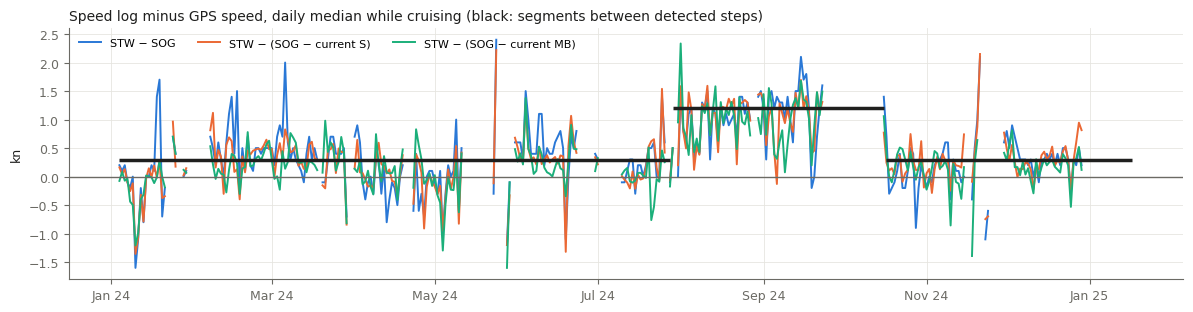

monthly median:
         STW − SOG  STW − (SOG − current S)  STW − (SOG − current MB)
time                                                                 
2024-01       0.00                    -0.02                     -0.02
2024-02       0.50                     0.46                      0.20
2024-03       0.40                     0.43                      0.26
2024-04      -0.10                     0.06                      0.07
2024-05      -0.05                    -0.17                     -0.23
2024-06       0.50                     0.34                      0.24
2024-07       0.20                     0.09                      0.04
2024-08       1.10                     1.22                      1.03
2024-09       1.30                     1.14                      1.08
2024-10       0.05                     0.13                      0.21
2024-11       0.15                     0.19                      0.15
2024-12       0.30                     0.29                      0.19
2025

In [10]:
dd = pd.DataFrame({
    "STW − SOG": T.daily(diff, "median"),
    "STW − (SOG − current S)": T.daily((w.stw_kn - (w.sog_kn - w.cur_s)).where(cruising), "median"),
    "STW − (SOG − current MB)": T.daily((w.stw_kn - (w.sog_kn - w.cur_mb)).where(cruising), "median"),
})
steps_diff = T.find_steps(dd["STW − SOG"])
display(steps_diff.round(2))
fig, ax = plt.subplots(figsize=(12, 3.2))
for col, c in zip(dd.columns, [BLUE, ORANGE, AQUA]):
    ax.plot(dd.index, dd[col], color=c, lw=1.4, label=col)
for _, s in steps_diff.iterrows():
    ax.hlines(s["median"], pd.Timestamp(s["from"]), pd.Timestamp(s["to"]), color=INK, lw=2.5)
ax.axhline(0, color=MUTED, lw=1)
ax.set_ylabel("kn"); ax.legend(frameon=False, ncol=3, fontsize=8, loc="upper left")
ax.set_title("Speed log minus GPS speed, daily median while cruising (black: segments between detected steps)", loc="left", color=INK)
month_axis(ax); fig.tight_layout(); plt.show()
print("monthly median:"); print(dd.groupby(dd.index.to_period("M")).median().round(2).to_string())

### 6c. Real current or sensor offset? Test by heading

A real current pushes the ship from one side: sailing east and sailing west give **opposite** STW − SOG. A speed-log offset is the **same in every direction**. Median STW − SOG per heading sector and period (hours of data in brackets).

In [11]:
seg = steps_diff
periods = {f"{a} – {b}": (str(a), str(b)) for a, b in zip(seg["from"], seg["to"])}
sector = pd.cut(w.heading_deg % 360, [0, 45, 135, 225, 315, 360], labels=["N", "E", "S", "W", "N "], include_lowest=True)
sector = sector.astype(str).str.strip()
tab = {}
for name, (a, b) in periods.items():
    x = diff.loc[a:b]; s_ = sector.loc[a:b]
    g = x.groupby(s_)
    tab[name] = g.median().round(2).astype(str) + " (" + (g.count() * 15 / 3600).round(0).astype(int).astype(str) + " h)"
heading_test = pd.DataFrame(tab).reindex(["N", "E", "S", "W"])
heading_test

,2024-01-04 – 2024-07-28,2024-07-29 – 2024-10-16,2024-10-17 – 2025-01-17
heading_deg,,,
N,0.5 (558 h),1.2 (106 h),0.3 (553 h)
E,0.4 (1095 h),1.2 (669 h),0.4 (102 h)
S,0.2 (208 h),1.1 (325 h),0.0 (111 h)
W,0.0 (1303 h),1.4 (2 h),0.2 (578 h)


### 6d. Apparent slip: speed against engine rpm

The propeller (pitch 4.58 m) screws through the water at `pitch × rpm`. **Apparent slip = 1 − speed / (pitch × rpm)**, usually 0–20 %. Computed with STW and with SOG, split by loading (laden ships slip more). Engine rpm is the independent reference.

- If the **speed log** reads too high, slip from STW drops (can go negative) while slip from SOG stays normal.
- Fouling raises slip slowly with both speeds.

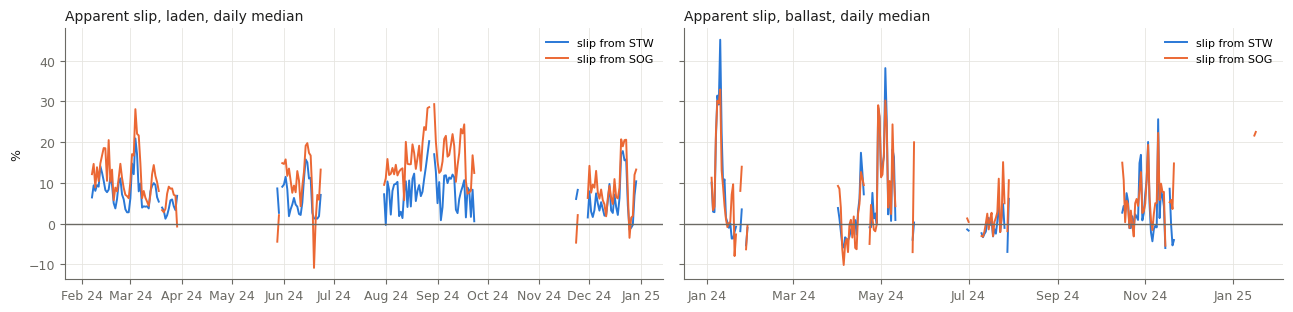

period         2024-01-04 – 2024-07-28  2024-07-29 – 2024-10-16  2024-10-17 – 2025-01-17
loading speed                                                                           
ballast SOG                        1.9                     14.9                      4.5
        STW                        0.6                      2.7                      1.8
laden   SOG                       10.2                     15.2                      7.3
        STW                        6.8                      8.5                      3.9

In [12]:
pitch_kn = T.PITCH_M * w.me_rpm / 60 * T.KN
slip = pd.DataFrame({"STW": 100 * (1 - w.stw_kn / pitch_kn), "SOG": 100 * (1 - w.sog_kn / pitch_kn)}).where(cruising, np.nan)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.2), sharey=True)
rows = []
for ax, (lab, m) in zip(axes, [("laden", laden), ("ballast", ~laden)]):
    for col, c in [("STW", BLUE), ("SOG", ORANGE)]:
        d_ = T.daily(slip[col].where(m), "median")
        ax.plot(d_.index, d_, color=c, lw=1.4, label=f"slip from {col}")
        for (pname, (a, b)) in periods.items():
            rows.append({"loading": lab, "speed": col, "period": pname, "median slip %": round(slip[col].where(m).loc[a:b].median(), 1)})
    ax.axhline(0, color=MUTED, lw=1); ax.set_title(f"Apparent slip, {lab}, daily median", loc="left", color=INK)
    month_axis(ax); ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("%")
fig.tight_layout(); plt.show()
pd.DataFrame(rows).pivot_table(index=["loading", "speed"], columns="period", values="median slip %")

### 6e. Heading vs turn rate

The gyrocompass gives both. The change of heading per minute should match the turn rate.

In [13]:
dhdt = ((w.heading_deg.diff() + 180) % 360 - 180) * 4             # wrap-safe heading change, deg per minute (15 s steps)
ok = running & step_ok & w.turn_rate.notna() & dhdt.notna()
r_ = np.corrcoef(dhdt[ok].clip(-30, 30), w.turn_rate[ok].clip(-30, 30))[0, 1]
b_ = np.polyfit(w.turn_rate[ok].clip(-30, 30), dhdt[ok].clip(-30, 30), 1)[0]
print(f"heading change per minute vs turn rate: correlation {r_:.2f}, slope {b_:.2f} (expect 1.00), {int(ok.sum()):,} moments")
hr_ = pd.DataFrame({"dh": dhdt[ok], "tr": w.turn_rate[ok]}).resample("1h").mean().dropna()
print(f"hourly means: correlation {hr_.corr().iloc[0, 1]:.2f}")

heading change per minute vs turn rate: correlation 0.88, slope 0.83 (expect 1.00), 1,437,183 moments
hourly means: correlation 0.97


### 6f. Depth

The echosounder logs only part of the time. Shallow water (less than about 3 × the draft) raises resistance and must be excluded from the baseline (ISO 19030 uses a depth limit).

In [14]:
dp = w.depth_m.where(running)
print(f"depth readings while sailing: {int(dp.notna().sum()):,} of {int(running.sum()):,} moments ({100 * dp.notna().sum() / running.sum():.0f} %)")
print(f"median {dp.median():.0f} m; below 30 m: {100 * (dp < 30).mean() / dp.notna().mean():.1f} % of readings; below 50 m: {100 * (dp < 50).sum() / dp.notna().sum():.1f} %")
print("depth coverage while sailing, % per month:")
print((dp.notna().groupby(w.index.to_period("M")).sum() / running.groupby(w.index.to_period("M")).sum() * 100).round(0).to_string())

depth readings while sailing: 161,438 of 1,437,592 moments (11 %)
median 37 m; below 30 m: 40.2 % of readings; below 50 m: 60.9 %
depth coverage while sailing, % per month:


time
2024-01     6.0
2024-02     4.0
2024-03    21.0
2024-04    18.0
2024-05    20.0
2024-06    10.0
2024-07     8.0
2024-08     0.0
2024-09     2.0
2024-10     0.0
2024-11    21.0
2024-12    24.0
2025-01    10.0
Freq: M


## 7. Step changes: summary

In [15]:
summary = []
for name, ser in [("STW − SOG", dd["STW − SOG"]), ("slip from STW (all)", T.daily(slip["STW"], "median")),
                  ("slip from SOG (all)", T.daily(slip["SOG"], "median"))]:
    st = T.find_steps(ser)
    for _, s in st.iloc[1:].iterrows():
        summary.append({"series": name, "step_at": s["from"], "new_level": round(s["median"], 2),
                        "previous_level": round(st.loc[_ - 1, "median"], 2)})
pd.DataFrame(summary).sort_values("step_at")

,series,step_at,new_level,previous_level
2,slip from STW (all),2024-01-14,4.56,15.90
0,STW − SOG,2024-07-29,1.20,0.30
3,slip from SOG (all),2024-08-04,16.05,7.99
4,slip from SOG (all),2024-09-20,6.37,16.05
1,STW − SOG,2024-10-17,0.30,1.20


## 8. Findings and trust table

Trust per signal and month, while sailing with the engine running:
- **bad:** more than 10 % of moments affected, or a known offset (STW during the offset period(s) from 6b/6c)
- **suspect:** 1–10 % affected; **OK:** under 1 %; **no data:** no readings

"Affected" = fake zero, stuck run, out of range, or spike.

In [16]:
month = w.index.to_period("M")
aff = pd.DataFrame(False, index=w.index, columns=NAV)
for s in ["stw_kn", "sog_kn", "heading_deg", "turn_rate"]:
    for _, r__ in T.stuck_runs(w[s], running, 0.5).iterrows():
        aff.loc[r__.start:r__.end, s] = True
aff["stw_kn"] |= checks["STW = 0 while SOG > 3 kn"] | spk["STW jump > 1 kn"] | (w.stw_kn > T.LIMITS["stw_kn"][1])
aff["sog_kn"] |= checks["SOG = 0 while STW > 3 kn and engine turns"] | spk["SOG jump > 1 kn"] | (w.sog_kn > T.LIMITS["sog_kn"][1])
aff["heading_deg"] |= spk["heading jump > 10° without turn rate"]
aff["depth_m"] |= checks["depth = 0"]
share = aff[running].groupby(month[running]).mean() * 100
has = w.loc[running, NAV].notna().groupby(month[running]).mean()
trust = share.apply(lambda c: c.map(lambda x: "bad" if x > 10 else "suspect" if x > 1 else "OK")).where(has >= 0.05, "no data")
trust["depth_m"] = trust["depth_m"].where(has["depth_m"] >= 0.5, "sparse")
base = steps_diff["median"].iloc[0]
for _, s in steps_diff.iterrows():
    if s["median"] - base > 0.5:
        a, b = pd.Period(pd.Timestamp(s["from"]), "M"), pd.Period(pd.Timestamp(s["to"]), "M")
        trust.loc[(trust.index >= a) & (trust.index <= b), "stw_kn"] = "bad"
mon = diff.groupby(w.index.to_period("M")).median()
mon_h = hours(diff.notna().groupby(w.index.to_period("M")).sum())
for m_, v_ in mon.items():                      # months with an offset the step detection missed, if there is enough data
    if v_ - base > 0.5 and mon_h[m_] >= 24 and m_ in trust.index:
        trust.loc[m_, "stw_kn"] = "bad"
print("STW − SOG per month while cruising (median kn, hours of data):")
print(pd.DataFrame({"median_kn": mon.round(2), "hours": mon_h.round(0)}).T.to_string())
print("% of sailing moments affected"); display(share.round(1))
print("Trust"); display(trust)

STW − SOG per month while cruising (median kn, hours of data):
time       2024-01  2024-02  2024-03  2024-04  2024-05  2024-06  2024-07  2024-08  2024-09  2024-10  2024-11  2024-12  2025-01
median_kn      0.0      0.5      0.4     -0.1      0.0      0.5      0.2      1.1      1.3      0.0      0.3      0.3      1.0
hours        355.0    544.0    592.0    595.0    226.0    491.0    383.0    584.0    488.0    361.0    377.0    616.0      0.0
% of sailing moments affected


,stw_kn,sog_kn,heading_deg,turn_rate,depth_m
time,,,,,
2024-01,0.0,0.1,0.0,0.0,0.0
2024-02,0.0,0.5,0.0,0.0,0.0
2024-03,0.0,4.5,0.0,0.0,0.0
2024-04,0.0,1.7,0.0,0.0,0.0
2024-05,0.2,0.1,0.0,0.0,0.0
2024-06,0.0,0.8,0.0,0.0,0.0
2024-07,0.0,1.2,0.0,0.0,0.0
2024-08,0.0,0.0,0.0,0.0,0.0
2024-09,0.0,0.0,0.0,0.0,0.0


Trust


,stw_kn,sog_kn,heading_deg,turn_rate,depth_m
time,,,,,
2024-01,OK,OK,OK,OK,sparse
2024-02,OK,OK,OK,OK,sparse
2024-03,OK,suspect,OK,OK,sparse
2024-04,OK,suspect,OK,OK,sparse
2024-05,OK,OK,OK,OK,sparse
2024-06,OK,OK,OK,OK,sparse
2024-07,bad,suspect,OK,OK,sparse
2024-08,bad,OK,OK,OK,sparse
2024-09,bad,OK,OK,OK,sparse


In [17]:
off = steps_diff[steps_diff["median"] - steps_diff["median"].iloc[0] > 0.5]
for _, s in off.iterrows():
    col = f"{s['from']} – {s['to']}"
    sec = heading_test[col] if col in heading_test else None
    F.add("`stw_kn`", f"{s['from']} – {s['to']}", "drift or bias",
          f"Speed log reads {s['median']:+.2f} kn above GPS speed (vs {base:+.2f} kn before). The offset is the same in every heading "
          f"sector ({'; '.join(f'{k}: {v}' for k, v in sec.dropna().items()) if sec is not None else 'see 6c'}), so it is a sensor offset, "
          "not a current. Slip from GPS speed rises while slip from STW stays level, consistent with a speed log reading high",
          "§6b, §6c, §6d", f"{s['days']} days", "Speed too high → fouling hidden",
          "Use SOG (with currents averaged out over days), or STW minus the offset for this period")
F.add("`s_cur_e/n`, `mb_cur_e/n`", "all year", "other",
      f"Modelled currents explain only part of STW − SOG: slope {cur_fit.loc['S', 'slope (expect −1)']} (S) and "
      f"{cur_fit.loc['MB', 'slope (expect −1)']} (MB) instead of −1, correlation {cur_fit.loc['S', 'correlation']} / {cur_fit.loc['MB', 'correlation']}. "
      "Agrees with Fritz & Schmidt (HullPIC 2026) that the providers miss observed currents",
      "§6a", "all hours", "STW rebuilt from SOG − current is only partly corrected", "Prefer measured STW where the speed log is healthy")
F.add("`stw_kn`", "Jan–Jul 2024", "drift or bias",
      f"Even outside the offset period the speed log reads {base:+.2f} kn above GPS speed (median, cruising); modelled currents "
      f"do not remove it (intercept {cur_fit.loc['S', 'intercept [kn]']:+.2f} kn after current correction)", "§6a, §6b",
      "small", "About 2–3 % of speed; matters for absolute speed-loss levels, not for trends", "Note as a limitation")
jp = jan25_presence["% present while moving > 8 kn"]
F.add("all signals", "Jan 2025", "missing / gap",
      f"While the ship sails (above 8 kn, {hours(mov25.sum()):.0f} h), only GPS speed ({jp['sog_kn']:.0f} %), the speed log ({jp['stw_kn']:.0f} %) "
      f"and the hourly weather remain. Engine rpm ({jp['me_rpm']:.1f} %), heading ({jp['heading_deg']:.0f} %) and the ship's wind sensor "
      f"({jp['wind_rel_kn']:.0f} %) are missing at sea but present in port: removed on purpose for the blind test",
      "§1b", f"{hours(mov25.sum()):.0f} h of sailing", "No rpm- or power-based model can be applied to Jan 2025",
      "Use a speed-only method (speed vs loading and weather) for the Jan 2025 'current condition'")
dp_cov = 100 * dp.notna().sum() / running.sum()
F.add("`depth_m`", "all year", "missing / gap",
      f"Echosounder logs only {dp_cov:.0f} % of sailing time (0–2 % in Aug–Oct), and {100 * (dp < 30).sum() / dp.notna().sum():.0f} % "
      "of its readings are below 30 m: it seems to be switched on mainly in coastal or shallow water",
      "§6f", f"{dp_cov:.0f} % coverage", "Cannot be used as an ISO 19030 shallow-water filter for most of the year",
      "Treat missing depth as unknown, not deep; flag shallow readings")
sog_st = T.stuck_runs(w.sog_kn, running, 0.5)
if len(sog_st):
    F.add("`sog_kn`", f"{len(sog_st)} runs, mostly {sog_st.start.dt.to_period('M').mode()[0]}", "stuck or placeholder value",
          f"GPS speed stays exactly constant for 30 min or more while sailing ({sog_st.hours.sum():.0f} h in total, longest "
          f"{sog_st.hours.max():.1f} h). Speed is logged in 0.1 kn steps, so some flat runs are normal, but hours-long ones suggest a GPS hold",
          "§3", f"{sog_st.hours.sum():.0f} h", "Small", "Flag; check against STW in those runs")
neg = (w.stw_kn < 0)
F.add("`stw_kn`", "stops", "other", f"Speed log negative in {int(neg.sum()):,} moments, almost all while stopped (water flowing past "
      "a moored or anchored ship); see also DQ-11", "§4", f"{int(neg.sum()):,} moments", "Harmless if stops are excluded", "Exclude stops")
F.table()

,signal,period,type,what,evidence,affected,impact,options
0,`stw_kn`,2024-07-29 – 2024-10-16,drift or bias,Speed log reads +1.20 kn above GPS speed (vs +...,"02_speed_navigation §6b, §6c, §6d",55 days,Speed too high → fouling hidden,Use SOG (with currents averaged out over days)...
1,"`s_cur_e/n`, `mb_cur_e/n`",all year,other,Modelled currents explain only part of STW − S...,02_speed_navigation §6a,all hours,STW rebuilt from SOG − current is only partly ...,Prefer measured STW where the speed log is hea...
2,`stw_kn`,Jan–Jul 2024,drift or bias,Even outside the offset period the speed log r...,"02_speed_navigation §6a, §6b",small,About 2–3 % of speed; matters for absolute spe...,Note as a limitation
3,all signals,Jan 2025,missing / gap,"While the ship sails (above 8 kn, 65 h), only ...",02_speed_navigation §1b,65 h of sailing,No rpm- or power-based model can be applied to...,Use a speed-only method (speed vs loading and ...
4,`depth_m`,all year,missing / gap,Echosounder logs only 11 % of sailing time (0–...,02_speed_navigation §6f,11 % coverage,Cannot be used as an ISO 19030 shallow-water f...,"Treat missing depth as unknown, not deep; flag..."
5,`sog_kn`,"69 runs, mostly 2024-03",stuck or placeholder value,GPS speed stays exactly constant for 30 min or...,02_speed_navigation §3,52 h,Small,Flag; check against STW in those runs
6,`stw_kn`,stops,other,"Speed log negative in 92,782 moments, almost a...",02_speed_navigation §4,"92,782 moments",Harmless if stops are excluded,Exclude stops


In [18]:
print(F.markdown_rows(first_id=19))

| DQ-19 | `stw_kn` | 2024-07-29 – 2024-10-16 | drift or bias | Speed log reads +1.20 kn above GPS speed (vs +0.30 kn before). The offset is the same in every heading sector (N: 1.2 (106 h); E: 1.2 (669 h); S: 1.1 (325 h); W: 1.4 (2 h)), so it is a sensor offset, not a current. Slip from GPS speed rises while slip from STW stays level, consistent with a speed log reading high | 02_speed_navigation §6b, §6c, §6d | 55 days | Speed too high → fouling hidden | Use SOG (with currents averaged out over days), or STW minus the offset for this period | | open | mp, 28 Oct |
| DQ-20 | `s_cur_e/n`, `mb_cur_e/n` | all year | other | Modelled currents explain only part of STW − SOG: slope -0.93 (S) and -0.78 (MB) instead of −1, correlation -0.54 / -0.61. Agrees with Fritz & Schmidt (HullPIC 2026) that the providers miss observed currents | 02_speed_navigation §6a | all hours | STW rebuilt from SOG − current is only partly corrected | Prefer measured STW where the speed log is healthy | | open | mp,

## Notes

Write your own observations here.